# MediaPipe vs SAM 3D Body on all three exercises

The arm-abduction comparison found that SAM 3D Body poses give a better classifier than MediaPipe poses in
every configuration, and that the gain is largest where the exercising arm is hidden from the camera. Arm
abduction is the exercise MediaPipe was weakest on, so this notebook repeats the comparison on the whole
dataset and asks two questions:

1. **Does the gain hold for squat and shoulder extension?**
2. **Does a better pose model shrink the viewpoint gap?** The dataset paper reports that camera placement
   changes how well errors can be separated. If better poses flatten accuracy across viewing angles, a
   single camera needs less careful placement.

- **Data:** every repetition of the four development participants, all three exercises and cameras. The
  held-out test participant is excluded before anything else happens.
- **Split:** each participant takes a turn as the unseen validation participant; three seeds.
- **Models:** one model for all three exercises, as in the earlier all-exercise notebooks.
- **Poses:** MediaPipe on every frame; SAM 3D Body in body-only mode on every third frame. Both are
  resampled to 64 time steps. Coordinate features use the 17 body joints both models estimate directly.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from rehab26.data import DATA_DIR, EX_NAME, load_dataset, participant_folds
from rehab26.features import biomech_features, canonicalize_rotation, normalize_by_group, scale_normalize
from rehab26.sam3d import load_sam3d
from rehab26.train import run_condition

EXERCISES = (1, 6, 7)
TEST_PERSON = "Vasil"
SEEDS = (0, 1, 2)
FIG = "../docs/figures"
BODY = [0, 11, 12, 13, 14, 15, 16, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32]
pd.set_option("display.width", 220)

X, full_meta = load_dataset(n_frames=64)
dev = full_meta.reset_index()
dev = dev[(dev.person != TEST_PERSON) & dev.exercise_id.isin(EXERCISES)]

sam_parts, sam_index, offset = [], [], 0
for ex in EXERCISES:
    out_dir = DATA_DIR / f"sam3d/ex{ex}"
    if not any(out_dir.glob("rep*_cam*.npz")):
        raise RuntimeError(f"no SAM 3D Body poses in {out_dir}: the extraction run has not reached exercise {ex}")
    P_ex, idx_ex = load_sam3d(out_dir, n_frames=64)
    sam_parts.append(P_ex)
    sam_index.append(idx_ex.assign(sam_row=np.arange(len(idx_ex)) + offset))
    offset += len(idx_ex)
P_sam, idx = np.concatenate(sam_parts), pd.concat(sam_index, ignore_index=True)

meta = dev.merge(idx, on=["rep_id", "cam"]).sort_values(["rep_id", "cam"]).reset_index(drop=True)
if len(meta) != len(dev):
    missing = dev.merge(idx, on=["rep_id", "cam"], how="left", indicator=True).query("_merge == 'left_only'")
    raise RuntimeError(f"SAM 3D Body poses are missing for {len(missing)} of {len(dev)} development sequences "
                       f"(by exercise: {missing.exercise_id.value_counts().to_dict()}). Finish the extraction run first.")
assert TEST_PERSON not in set(meta.person)

POSES = {"MediaPipe": X[meta["index"].values][..., :3], "SAM 3D Body": P_sam[meta.sam_row.values]}
FOLDS = participant_folds(meta, test_person=TEST_PERSON)

print("sequences:", len(meta), "| repetitions:", meta.rep_id.nunique(), "| incorrect share: %.2f" % meta.y.mean())
print("by exercise:", meta.groupby("exercise").size().to_dict())
print("folds:", [(v, len(tr), len(va)) for tr, va, v in FOLDS])
print("SAM 3D Body frames:", int(meta.n_samples.sum()), "| failed:", int(meta.failed.sum()))
print("device:", "cuda" if torch.cuda.is_available() else "cpu")

sequences: 3981 | repetitions: 1327 | incorrect share: 0.50
by exercise: {'Arm abduction': 1329, 'Shoulder extension': 1329, 'Squat': 1323}
folds: [('Honza', 2988, 993), ('Mima', 2976, 1005), ('Petra', 2988, 993), ('Terka', 2991, 990)]
SAM 3D Body frames: 127677 | failed: 0
device: cuda


## 1. Features and training

Three feature sets, built identically from both pose sources:

- **scaled**: body-joint coordinates divided by torso length.
- **aligned**: scaled, then rotated about the vertical so the starting pose faces the camera.
- **biomech**: joint angles, segment tilts and width ratios with their velocities.

Each is run with and without per-recording normalization: every feature is z-scored within each
participant's recording of an exercise, using all of that recording's repetitions and no labels.

In [2]:
def features(P):
    n, t = P.shape[:2]
    scaled = scale_normalize(P)
    return {"scaled": scaled[:, :, BODY].reshape(n, t, -1),
            "aligned": canonicalize_rotation(scaled)[:, :, BODY].reshape(n, t, -1),
            "biomech": biomech_features(P)[0]}

FEATURES = {src: features(P) for src, P in POSES.items()}
KEYS, KINDS, NORMS = ("scaled", "aligned", "biomech"), ("mlp", "cnn"), ("none", "per-recording")
recording = (meta.person + "_" + meta.exercise_id.astype(str)).values

all_scores, all_preds = [], []
for kind in KINDS:
    for key in KEYS:
        for norm in NORMS:
            for src in POSES:
                seq = FEATURES[src][key]
                if norm == "per-recording":
                    seq = normalize_by_group(seq, recording)
                s, p, _ = run_condition(f"{kind.upper()} | {key} | {norm} | {src}", kind, seq, meta, FOLDS, SEEDS)
                tags = dict(model=kind.upper(), features=key, norm=norm, source=src)
                all_scores.append(s.assign(**tags)); all_preds.append(p.assign(**tags))
scores, preds = pd.concat(all_scores), pd.concat(all_preds)
preds["hit"] = (preds.pred == preds.y).astype(float)

MLP | scaled | none | MediaPipe          val acc 0.700  (24s)


MLP | scaled | none | SAM 3D Body        val acc 0.743  (22s)


MLP | scaled | per-recording | MediaPipe val acc 0.764  (21s)


MLP | scaled | per-recording | SAM 3D Body val acc 0.820  (21s)


MLP | aligned | none | MediaPipe         val acc 0.699  (22s)


MLP | aligned | none | SAM 3D Body       val acc 0.751  (22s)


... (14 outputs left out)

CNN | biomech | none | MediaPipe         val acc 0.744  (34s)


CNN | biomech | none | SAM 3D Body       val acc 0.812  (34s)


CNN | biomech | per-recording | MediaPipe val acc 0.764  (34s)


CNN | biomech | per-recording | SAM 3D Body val acc 0.872  (34s)


## 2. Overall results

Validation accuracy on the unseen participant, averaged over participants and seeds. `difference` is
SAM 3D Body minus MediaPipe; `folds_better` counts in how many of the four participants SAM 3D Body was
ahead.

source                        MediaPipe  SAM 3D Body  difference  folds_better
model features norm                                                           
MLP   scaled   none               0.700        0.743       0.043             2
               per-recording      0.764        0.820       0.056             4
      aligned  none               0.699        0.751       0.052             3
               per-recording      0.783        0.863       0.080             4
      biomech  none               0.729        0.783       0.054             4
               per-recording      0.741        0.829       0.087             4
CNN   scaled   none               0.731        0.771       0.040             4
               per-recording      0.760        0.866       0.106             4
      aligned  none               0.704        0.780       0.076             4
               per-recording      0.766        0.861       0.095             4
      biomech  none               0.744        0.812       0.068             4
               per-recording      0.764        0.872       0.108             4

acc    auc  recall  specificity  train_loss  val_loss
model features norm          source                                                              
MLP   scaled   none          MediaPipe    0.700  0.821   0.811        0.589       0.248     0.997
                             SAM 3D Body  0.743  0.866   0.853        0.632       0.145     1.048
               per-recording MediaPipe    0.764  0.858   0.808        0.720       0.190     0.714
                             SAM 3D Body  0.820  0.928   0.910        0.730       0.101     0.582
      aligned  none          MediaPipe    0.699  0.827   0.815        0.583       0.226     1.063
                             SAM 3D Body  0.751  0.880   0.867        0.635       0.070     1.473
               per-recording MediaPipe    0.783  0.874   0.838        0.728       0.161     0.700
                             SAM 3D Body  0.863  0.952   0.928        0.799       0.039     0.665
      biomech  none          MediaPipe    0.729  0.812   0.802        0.656       0.177     1.037
                             SAM 3D Body  0.783  0.906   0.863        0.703       0.055     0.994
               per-recording MediaPipe    0.741  0.839   0.808        0.674       0.120     0.965
                             SAM 3D Body  0.829  0.921   0.907        0.751       0.030     0.894
CNN   scaled   none          MediaPipe    0.731  0.839   0.832        0.629       0.156     1.047
                             SAM 3D Body  0.771  0.859   0.853        0.689       0.095     1.298
               per-recording MediaPipe    0.760  0.862   0.844        0.675       0.110     0.865
                             SAM 3D Body  0.866  0.938   0.898        0.833       0.065     0.485
      aligned  none          MediaPipe    0.704  0.820   0.831        0.576       0.138     1.432
                             SAM 3D Body  0.780  0.884   0.871        0.689       0.051     1.178
               per-recording MediaPipe    0.766  0.868   0.846        0.686       0.087     0.898
                             SAM 3D Body  0.861  0.953   0.926        0.795       0.023     0.567
      biomech  none          MediaPipe    0.744  0.836   0.827        0.662       0.047     1.451
                             SAM 3D Body  0.812  0.930   0.907        0.717       0.018     1.021
               per-recording MediaPipe    0.764  0.854   0.839        0.689       0.029     1.256
                             SAM 3D Body  0.872  0.955   0.920        0.824       0.013     0.530

Mean over all 12 configurations:


source,MediaPipe,SAM 3D Body
acc,0.74,0.813


Accuracy per unseen participant, mean over configurations:


val_person,Honza,Mima,Petra,Terka
source,,,,
MediaPipe,0.689,0.758,0.799,0.716
SAM 3D Body,0.797,0.827,0.866,0.761


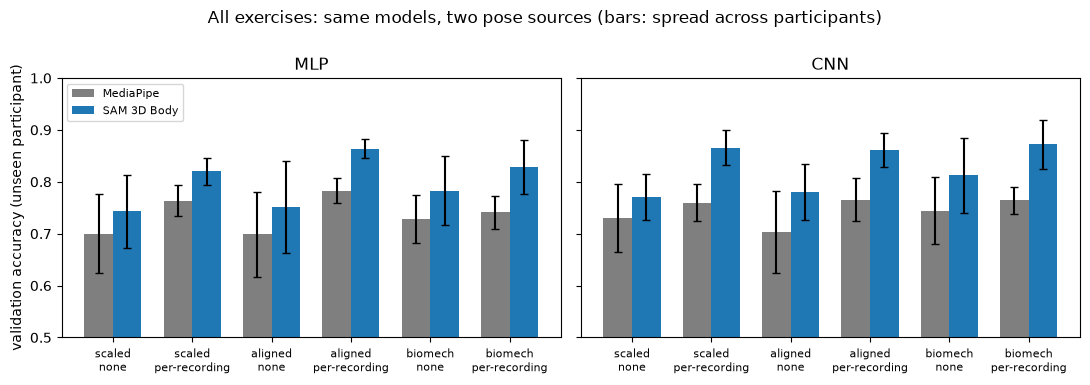

In [3]:
G = ["model", "features", "norm"]
acc = scores.groupby(G + ["source"], sort=False).acc.mean().unstack()
acc["difference"] = acc["SAM 3D Body"] - acc["MediaPipe"]
by_person = scores.groupby(G + ["val_person", "source"], sort=False).acc.mean().unstack()
acc["folds_better"] = (by_person["SAM 3D Body"] > by_person["MediaPipe"]).groupby(G, sort=False).sum()
display(acc.round(3))

detail = scores.groupby(G + ["source"], sort=False)[["acc", "auc", "recall", "specificity", "train_loss", "val_loss"]].mean()
display(detail.round(3))
print(f"Mean over all {len(acc)} configurations:"); display(scores.groupby("source").acc.mean().round(3).to_frame().T)
print("Accuracy per unseen participant, mean over configurations:")
display(scores.groupby(["source", "val_person"]).acc.mean().unstack().round(3))
acc.to_csv("../docs/part6_sam3d_all_exercises_results.csv")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
labels = [f"{k}\n{n}" for k in KEYS for n in NORMS]
xpos = np.arange(len(labels))
std = scores.groupby(G + ["source", "val_person"], sort=False).acc.mean().groupby(G + ["source"], sort=False).std().unstack()
for ax, kind in zip(axes, KINDS):
    for off, src, color in [(-0.18, "MediaPipe", "tab:gray"), (0.18, "SAM 3D Body", "tab:blue")]:
        rows = [(kind.upper(), k, n) for k in KEYS for n in NORMS]
        ax.bar(xpos + off, acc.loc[rows, src], 0.36, yerr=std.loc[rows, src], capsize=3, color=color, label=src)
    ax.set_xticks(xpos); ax.set_xticklabels(labels, fontsize=8); ax.set_title(kind.upper()); ax.set_ylim(0.5, 1.0)
axes[0].set_ylabel("validation accuracy (unseen participant)"); axes[0].legend(fontsize=8, loc="upper left")
fig.suptitle("All exercises: same models, two pose sources (bars: spread across participants)", y=1.0)
fig.tight_layout(); fig.savefig(f"{FIG}/fig_p6_sources.png", dpi=150); plt.show()

## 3. Does the gain hold for every exercise?

Accuracy by exercise, pooled over all configurations and then split by normalization. A model's score on
one exercise comes from the same all-exercise model, so these are breakdowns, not separately trained models.

In [4]:
by_ex = preds.groupby(["exercise", "source"]).hit.mean().unstack()
by_ex["difference"] = by_ex["SAM 3D Body"] - by_ex["MediaPipe"]
print("By exercise, all configurations:"); display(by_ex.round(3))

by_ex_norm = preds.groupby(["exercise", "norm", "source"], sort=False).hit.mean().unstack()
by_ex_norm["difference"] = by_ex_norm["SAM 3D Body"] - by_ex_norm["MediaPipe"]
print("By exercise and normalization:"); display(by_ex_norm.round(3))

ex_person = preds.groupby(["exercise", "person", "source"]).hit.mean().unstack()
ex_person["difference"] = ex_person["SAM 3D Body"] - ex_person["MediaPipe"]
print("By exercise and unseen participant (is the direction consistent?):"); display(ex_person.round(3))

By exercise, all configurations:


source,MediaPipe,SAM 3D Body,difference
exercise,,,
Arm abduction,0.648,0.743,0.094
Shoulder extension,0.786,0.852,0.066
Squat,0.787,0.843,0.056


By exercise and normalization:


source                            MediaPipe  SAM 3D Body  difference
exercise           norm                                             
Arm abduction      none               0.630        0.707       0.077
                   per-recording      0.666        0.778       0.112
Squat              none               0.763        0.821       0.058
                   per-recording      0.811        0.865       0.054
Shoulder extension none               0.760        0.792       0.032
                   per-recording      0.812        0.912       0.100

By exercise and unseen participant (is the direction consistent?):


source                     MediaPipe  SAM 3D Body  difference
exercise           person                                    
Arm abduction      Honza       0.612        0.705       0.093
                   Mima        0.596        0.687       0.091
                   Petra       0.688        0.796       0.107
                   Terka       0.698        0.784       0.086
Shoulder extension Honza       0.773        0.900       0.128
                   Mima        0.843        0.919       0.076
                   Petra       0.767        0.866       0.099
                   Terka       0.760        0.722      -0.038
Squat              Honza       0.682        0.783       0.101
                   Mima        0.834        0.875       0.040
                   Petra       0.943        0.937      -0.006
                   Terka       0.689        0.777       0.088

## 4. Does a better pose model shrink the viewpoint gap?

Accuracy by viewing angle for each exercise. A viewing angle of 0° is frontal; negative angles put the
participant's right side away from the camera. `spread` is the best view group minus the worst: the smaller
it is, the less camera placement matters. `frontal` is the group containing 0°.

View groups hold different repetitions and different numbers of them, so small differences between
neighbouring groups should not be read into.

Sequences per view group:


view_bin,-90 to -61,-60 to -31,-30 to -1,0 to 30,31 to 60,61 to 90
exercise,,,,,,
Arm abduction,161,240,202,363,241,122
Shoulder extension,161,243,201,362,242,120
Squat,161,240,201,361,240,120


All configurations:


view_bin                        -90 to -61  -60 to -31  -30 to -1  0 to 30  31 to 60  61 to 90  worst   best  spread  frontal
exercise           source                                                                                                    
Arm abduction      MediaPipe         0.552       0.650      0.632    0.681     0.672     0.655  0.552  0.681   0.129    0.681
                   SAM 3D Body       0.715       0.724      0.711    0.769     0.776     0.725  0.711  0.776   0.065    0.769
Shoulder extension MediaPipe         0.684       0.757      0.803    0.804     0.840     0.787  0.684  0.840   0.156    0.804
                   SAM 3D Body       0.836       0.831      0.858    0.867     0.867     0.833  0.831  0.867   0.036    0.867
Squat              MediaPipe         0.768       0.804      0.765    0.808     0.795     0.738  0.738  0.808   0.070    0.808
                   SAM 3D Body       0.842       0.874      0.843    0.853     0.838     0.761  0.761  0.874   0.113    0.853

With per-recording normalization only:


view_bin                        -90 to -61  -60 to -31  -30 to -1  0 to 30  31 to 60  61 to 90  worst   best  spread  frontal
exercise           source                                                                                                    
Arm abduction      MediaPipe         0.540       0.649      0.656    0.718     0.701     0.662  0.540  0.718   0.178    0.718
                   SAM 3D Body       0.704       0.745      0.761    0.824     0.816     0.760  0.704  0.824   0.120    0.824
Shoulder extension MediaPipe         0.699       0.766      0.843    0.851     0.871     0.769  0.699  0.871   0.172    0.851
                   SAM 3D Body       0.885       0.890      0.933    0.933     0.926     0.867  0.867  0.933   0.066    0.933
Squat              MediaPipe         0.780       0.835      0.800    0.840     0.811     0.741  0.741  0.840   0.100    0.840
                   SAM 3D Body       0.819       0.900      0.871    0.885     0.867     0.784  0.784  0.900   0.116    0.885

Viewpoint spread (best minus worst view group) by pose source:


source,MediaPipe,SAM 3D Body,reduction
exercise,,,
Arm abduction,0.129,0.065,0.064
Shoulder extension,0.156,0.036,0.120
Squat,0.070,0.113,-0.043


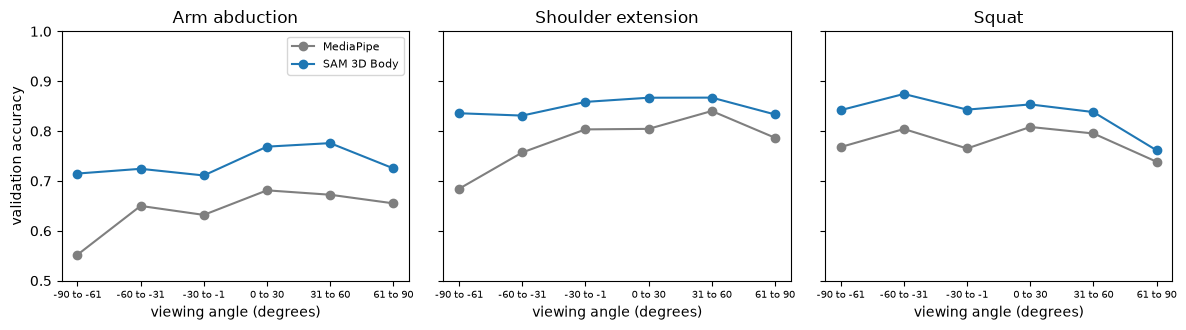

In [5]:
BINS = [-91, -60, -30, -1, 30, 60, 91]
BIN_LABELS = ["-90 to -61", "-60 to -31", "-30 to -1", "0 to 30", "31 to 60", "61 to 90"]
preds["view_bin"] = pd.cut(preds["view"], BINS, labels=BIN_LABELS)

def view_table(p):
    t = p.groupby(["exercise", "source", "view_bin"], observed=True).hit.mean().unstack()
    views = t[BIN_LABELS].copy()
    t["worst"], t["best"] = views.min(axis=1), views.max(axis=1)
    t["spread"] = t["best"] - t["worst"]
    t["frontal"] = views["0 to 30"]
    return t

print("Sequences per view group:")
display(meta.assign(view_bin=pd.cut(meta["view"], BINS, labels=BIN_LABELS)).groupby(["exercise", "view_bin"], observed=True).size().unstack())
by_view = view_table(preds)
print("All configurations:"); display(by_view.round(3))
by_view_norm = view_table(preds[preds.norm == "per-recording"])
print("With per-recording normalization only:"); display(by_view_norm.round(3))

gap = by_view["spread"].unstack()
gap["reduction"] = gap["MediaPipe"] - gap["SAM 3D Body"]
print("Viewpoint spread (best minus worst view group) by pose source:"); display(gap.round(3))

fig, axes = plt.subplots(1, len(by_view.index.levels[0]), figsize=(12, 3.4), sharey=True)
for ax, ex in zip(np.atleast_1d(axes), by_view.index.levels[0]):
    for src, color in [("MediaPipe", "tab:gray"), ("SAM 3D Body", "tab:blue")]:
        ax.plot(BIN_LABELS, by_view.loc[(ex, src), BIN_LABELS], "o-", color=color, label=src)
    ax.set_title(ex); ax.set_xlabel("viewing angle (degrees)"); ax.tick_params(axis="x", labelsize=7); ax.set_ylim(0.5, 1.0)
np.atleast_1d(axes)[0].set_ylabel("validation accuracy"); np.atleast_1d(axes)[0].legend(fontsize=8)
fig.tight_layout(); fig.savefig(f"{FIG}/fig_p6_view.png", dpi=150); plt.show()

## 5. One camera with better poses, or two cameras?

The dataset paper finds that adding a second, orthogonal camera (camera 1 with camera 3) improves error
separability. Every repetition here was filmed by all three cameras, so the same question can be asked of
the classifier: average the predicted probabilities of the single-view model over two or three cameras of
the same repetition, and score the result.

This is the simplest form of fusion. It combines predictions, not poses, so it is not the paper's
triangulation or pose fusion, and the models were never trained to use two views. The comparison of
interest is one camera with SAM 3D Body against two cameras with MediaPipe.

In [6]:
K = G + ["source", "seed", "exercise", "rep_id"]

def fused(cams):
    f = preds[preds.cam.isin(cams)].groupby(K, sort=False).agg(prob=("prob", "mean"), y=("y", "first")).reset_index()
    return f.assign(hit=((f.prob > 0.5) == (f.y == 1)).astype(float))

SETTINGS = {"camera 1 only": (1,), "camera 2 only": (2,), "camera 3 only": (3,),
            "cameras 1 + 3 averaged": (1, 3), "all three averaged": (1, 2, 3)}
fusion = pd.concat({name: fused(cams) for name, cams in SETTINGS.items()}, names=["cameras"]).reset_index(level=0)

def fusion_table(f):
    t = f.groupby(["cameras", "source"], sort=False).hit.mean().unstack()
    t["difference"] = t["SAM 3D Body"] - t["MediaPipe"]
    return t

print("All exercises, all configurations:"); display(fusion_table(fusion).round(3))
print("With per-recording normalization only:"); display(fusion_table(fusion[fusion.norm == "per-recording"]).round(3))
print("By exercise, all configurations:")
display(fusion.groupby(["exercise", "cameras", "source"], sort=False).hit.mean().unstack().round(3))

single = fusion[fusion.cameras.str.endswith("only")].groupby("source").hit.mean()
pair = fusion[fusion.cameras == "cameras 1 + 3 averaged"].groupby("source").hit.mean()
print("Average single camera vs cameras 1 + 3:")
display(pd.DataFrame({"one camera": single, "two cameras": pair, "gain from second camera": pair - single}).round(3))
print("One camera with SAM 3D Body: %.3f | two cameras with MediaPipe: %.3f" % (single["SAM 3D Body"], pair["MediaPipe"]))

All exercises, all configurations:


source,MediaPipe,SAM 3D Body,difference
cameras,,,
camera 1 only,0.703,0.800,0.097
camera 2 only,0.756,0.818,0.061
camera 3 only,0.762,0.820,0.058
cameras 1 + 3 averaged,0.777,0.834,0.057
all three averaged,0.785,0.838,0.053


With per-recording normalization only:


source,MediaPipe,SAM 3D Body,difference
cameras,,,
camera 1 only,0.718,0.828,0.110
camera 2 only,0.788,0.864,0.076
camera 3 only,0.784,0.863,0.079
cameras 1 + 3 averaged,0.814,0.884,0.071
all three averaged,0.828,0.890,0.061


By exercise, all configurations:


source                                     MediaPipe  SAM 3D Body
exercise           cameras                                       
Arm abduction      camera 1 only               0.613        0.725
                   camera 2 only               0.661        0.742
                   camera 3 only               0.671        0.762
                   cameras 1 + 3 averaged      0.682        0.765
                   all three averaged          0.690        0.766
Squat              camera 1 only               0.763        0.835
                   camera 2 only               0.796        0.856
                   camera 3 only               0.803        0.838
                   cameras 1 + 3 averaged      0.820        0.859
                   all three averaged          0.823        0.867
Shoulder extension camera 1 only               0.733        0.840
                   camera 2 only               0.812        0.855
                   camera 3 only               0.812        0.862
                   cameras 1 + 3 averaged      0.830        0.880
                   all three averaged          0.843        0.882

Average single camera vs cameras 1 + 3:


,one camera,two cameras,gain from second camera
source,,,
MediaPipe,0.740,0.777,0.037
SAM 3D Body,0.813,0.834,0.022


One camera with SAM 3D Body: 0.813 | two cameras with MediaPipe: 0.777


## 6. Which errors are caught

The share of each error type that is classified correctly, pooled over all configurations. The `correct`
row is the share of correct repetitions that pass.

In [7]:
per_error = preds.groupby(["exercise", "error", "source"]).hit.mean().unstack()
per_error["sequences"] = meta.groupby(["exercise", "error"]).size()
per_error["difference"] = per_error["SAM 3D Body"] - per_error["MediaPipe"]
display(per_error.sort_values(["exercise", "sequences"], ascending=[True, False]).round(3))

source                                    MediaPipe  SAM 3D Body  sequences  difference
exercise           error                                                               
Arm abduction      correct                    0.540        0.618        663       0.078
                   ERR_BENT_ARM               0.688        0.765        135       0.077
                   ERR_HEAD_TO_SIDE           0.761        0.869        135       0.107
                   ERR_ARM_FORWARD            0.760        0.883        132       0.122
                   ERR_ELEVATED_SHOULDER      0.725        0.913        132       0.188
                   ERR_LOW_ABDUCTION          0.850        0.908        132       0.059
Shoulder extension correct                    0.737        0.820        663       0.083
                   ERR_ARM_TO_SIDE            0.670        0.719        135       0.050
                   ERR_BENT_ARM               0.749        0.861        135       0.112
                   ERR_ELEVATED_SHOULDER      0.842        0.935        132       0.093
                   ERR_TORSO_FORWARD          0.968        0.958        132      -0.009
                   ERR_TORSO_ROTATION         0.950        0.953        132       0.004
Squat              correct                    0.689        0.761        660       0.072
                   ERR_SHALLOW_SQUAT          0.886        0.913        135       0.027
                   ERR_KNEES_FORWARD          0.971        0.983        132       0.013
                   ERR_KNEES_INSIDE           0.804        0.864        132       0.060
                   ERR_LIFTED_HEELS           0.966        0.989        132       0.024
                   ERR_TORSO_TO_SIDE          0.798        0.874        132       0.076

## 7. Findings

Accuracy is on an unseen participant, averaged over four held-out participants and three seeds. The pooled
figures average over all twelve combinations of model, features and normalization.

**SAM 3D Body poses give a better classifier in every configuration, on every exercise.** Average accuracy
rises from 0.740 to 0.813. The gain is between 0.04 and 0.11 in all twelve configurations, and all four
participants are ahead in ten of them. By exercise the gain is 0.09 for arm abduction, 0.07 for shoulder
extension and 0.06 for squat, so the arm-abduction result was the largest case but not a special one.

**The two fixes still stack.** Per-recording normalization adds about 0.05 with MediaPipe poses and about
0.08 with SAM 3D Body poses. The best configurations are the CNN on biomechanical features (0.872) and on
scaled coordinates (0.866), both with SAM 3D Body and normalization. The best MediaPipe result is 0.783.
AUC rises from 0.81 to 0.87 with MediaPipe to 0.86 to 0.96 with SAM 3D Body.

**Better poses shrink the viewpoint gap for the two arm exercises, but not for squat.** The spread between
the best and worst view group falls from 0.13 to 0.07 for arm abduction and from 0.16 to 0.04 for shoulder
extension. For those two exercises the worst view with SAM 3D Body is about as good as the best view with
MediaPipe. For squat the spread grows from 0.07 to 0.11: SAM 3D Body is ahead in every view group, but
gains least in the 61° to 90° group (0.74 to 0.76), which stays the weak spot for both pose sources.

**One camera with SAM 3D Body beats two or three cameras with MediaPipe.** A single camera with SAM 3D Body
averages 0.813. Averaging MediaPipe predictions over cameras 1 and 3 gives 0.777, and over all three
cameras 0.785. A second camera adds 0.04 with MediaPipe and 0.02 with SAM 3D Body, less than the 0.07 from
changing the pose model. Camera choice also matters less: single-camera accuracy ranges from 0.70 to 0.76
with MediaPipe and from 0.80 to 0.82 with SAM 3D Body.

**Correct repetitions and subtle errors gain the most.** The share of correct repetitions that pass rises
by 0.07 to 0.08 in each exercise. The largest gains among errors are elevated shoulder, arm forward, bent
arm and head to side (0.08 to 0.19). Errors that move the whole torso or the knees were already caught 95%
of the time or more and do not change.

**Arm abduction is still the hardest exercise** at 0.74 pooled and 0.78 with normalization, and only 62%
of its correct repetitions pass. Models still memorize: training loss is near zero in every configuration.

### Limits

- Four participants. The gain is not uniform: one participant is worse with SAM 3D Body on shoulder
  extension (0.76 to 0.72), and one is unchanged on squat, where they were already at 0.94.
- The best configuration was picked using these same validation participants, so 0.87 is optimistic. The
  averages over configurations (0.813 against 0.740) are the safer comparison.
- The two-camera comparison averages the predictions of single-view models. Models trained on two views, or
  poses fused across views as in the dataset paper, could gain more from a second camera than this shows.
- View groups are 30° wide and hold 120 to 360 sequences each, and which repetitions fall in each group
  depends on the participant's orientation, so differences between neighbouring groups are not reliable.
- These are accuracy differences, not the dataset paper's separability score, so the sizes are not directly
  comparable with the paper's figures.
- Per-recording normalization assumes several unlabeled repetitions from the new person, and benefits from
  this dataset's even mix of correct and incorrect repetitions.
- SAM 3D Body takes about 0.18 s per frame on a laptop GPU; MediaPipe runs live. The person box for
  SAM 3D Body came from MediaPipe's landmarks.
- Arm abduction scores here (0.74 with SAM 3D Body) are a little lower than in the arm-abduction-only
  notebook (0.77), so training one model on all three exercises did not help that exercise.

### Next step

Choose the final configuration from these development results, then evaluate it once on the held-out
participant with both pose sources.